In [93]:
import pandas as pd
# load data
df = pd.read_csv('pm25.csv')
df.dtypes
# print(df.to_string()) 
#df.loc[0:2, "temperature"]

datetimeUtc     object
temperature    float64
humidity       float64
pm25           float64
dtype: object

In [86]:
from datetime import datetime
from datetime import timezone

df['datetimeUtc'] = pd.to_datetime(df['datetimeUtc'])
df.dtypes

datetimeUtc    datetime64[ns, UTC]
temperature                float64
humidity                   float64
pm25                       float64
dtype: object

In [97]:
# extract an subsection of the dataset
datax = df.iloc[0:500]
#datax.loc[0, 'temperature']=-51.0
#datax

In [98]:
# convert data to list of tuples
datalist = list(datax.itertuples(index=False, name=None))
display(len(datalist))
#display(datalist)

500

In [99]:
# Task 1: Filter out unrealistic temperature values (outliers)
def filter_temperature_outliers(data):
    return list(filter(lambda x: -50 <= x[1] <= 50, data))  # Temperature in the range of -50°C to 50°C

In [100]:
datalist[0] = (datalist[0][0], -51.0, datalist[0][2], datalist[0][3])
#datalist

In [103]:
data1 = filter_temperature_outliers(datalist)
display(len(data1))
#display(data1)

499

In [102]:
# Task 2: Convert temperatures from Celsius to Fahrenheit
def convert_to_fahrenheit(data):
    return list(map(lambda x: (x[0], (x[1] * 9/5) + 32, x[2], x[3]), data))  # Convert 2nd element (Temperature)

In [104]:
data2 = convert_to_fahrenheit(data1)
#data2

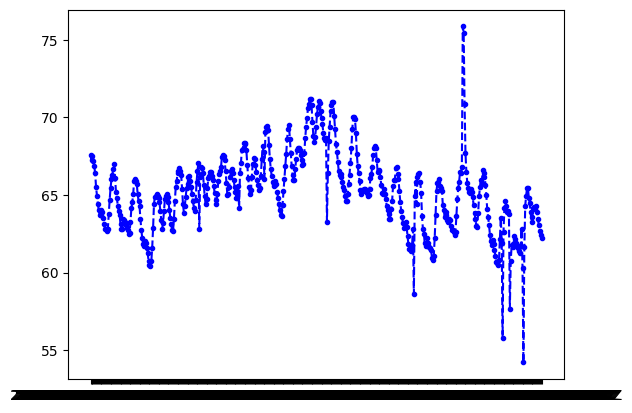

In [117]:
import matplotlib.pyplot as plt
templist = [(e0, e1) for e0, e1, e2, e3 in data2]
#display(templist)
ziplist = zip(*templist)
#display(ziplist)
plt.plot(*ziplist,linestyle='--', marker='.', color='b', label='temperature in Farenheit')
plt.show()

In [113]:
from collections import deque
# Task 3: Calculate 3-hour moving average for temperature
def moving_average(data, window_size=20):
    averages = []
    window = deque(maxlen=window_size)
    for timestamp, temp, humidity, air_quality in data:
        window.append(temp)
        if len(window) == window_size:
            avg_temp = sum(window) / len(window)
            averages.append((timestamp, avg_temp, humidity, air_quality))
    return averages

In [114]:
data3 = moving_average(data2)
display(len(data3))
#display(data3)

480

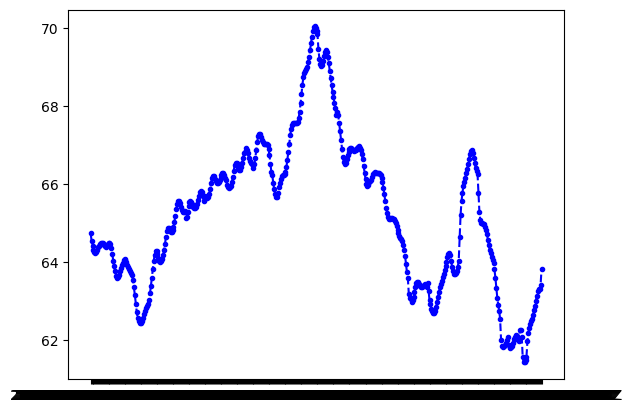

In [116]:
templist = [(e0, e1) for e0, e1, e2, e3 in data3]
#display(templist)
ziplist = zip(*templist)
#display(ziplist)
plt.plot(*ziplist,linestyle='--', marker='.', color='b', label='temperature moving average')
plt.show()

In [123]:
# Task 4: Apply a simple moving average for smoothing temperature data
def apply_smoothing(data, window_size=10):
    smoothed_data = []
    window = deque(maxlen=window_size)
    for timestamp, temp, humidity, air_quality in data:
        window.append(temp)
        smoothed_temp = sum(window) / len(window)  # SMA
        smoothed_data.append((timestamp, smoothed_temp, 
								humidity, air_quality))
    return smoothed_data

In [124]:
data4 = apply_smoothing(data3)
#data4

In [ ]:
templist = [(e0, e1) for e0, e1, e2, e3 in data4]
#display(templist)
ziplist = zip(*templist)
#display(ziplist)
plt.plot(*ziplist,linestyle='--', marker='.', color='b', label='temperature smoothing')
plt.show()

In [32]:
# Task 5: Impute missing temperature readings using forward filling
def impute_missing_data(data):
    filled_data = []
    last_value = None
    for record in data:
        if record[1] is not None:
            last_value = record[1]  # Update the last known value
        else:
            record = (record[0], last_value, record[2], record[3])  
		# Replace missing value with the last known value
        filled_data.append(record)
    return filled_data

In [41]:
data4[1]=(data4[1][0], None, data4[1][2], data4[1][3] )
data4

[('2025-02-25T15:00:00Z', 67.44062534, 50.17125003, 2.980541602),
 ('2025-02-25T16:00:00Z', None, 49.7253329, 20.12504164),
 ('2025-02-25T17:00:00Z', 67.31229186399999, 51.85599995, 18.39183346),
 ('2025-02-25T18:00:00Z', 67.1882688185, 53.41483402, 11.76054152),
 ('2025-02-25T19:00:00Z', 67.0008483428, 53.69140275, 13.7029167),
 ('2025-02-25T20:00:00Z', 66.63665660839999, 54.09987513, 15.32066679),
 ('2025-02-25T21:00:00Z', 66.165984896, 55.1059583, 12.54595836),
 ('2025-02-25T22:00:00Z', 65.6222199032, 55.82154115, 9.261874954)]

In [42]:
data5 = impute_missing_data(data4)
data5

[('2025-02-25T15:00:00Z', 67.44062534, 50.17125003, 2.980541602),
 ('2025-02-25T16:00:00Z', 67.44062534, 49.7253329, 20.12504164),
 ('2025-02-25T17:00:00Z', 67.31229186399999, 51.85599995, 18.39183346),
 ('2025-02-25T18:00:00Z', 67.1882688185, 53.41483402, 11.76054152),
 ('2025-02-25T19:00:00Z', 67.0008483428, 53.69140275, 13.7029167),
 ('2025-02-25T20:00:00Z', 66.63665660839999, 54.09987513, 15.32066679),
 ('2025-02-25T21:00:00Z', 66.165984896, 55.1059583, 12.54595836),
 ('2025-02-25T22:00:00Z', 65.6222199032, 55.82154115, 9.261874954)]

In [39]:
# main function
def process_iot_data(data):
    cleaned_data = filter_temperature_outliers(data)
    converted_data = convert_to_fahrenheit(cleaned_data)
    smoothed_data = apply_smoothing(converted_data)
    final_data = impute_missing_data(smoothed_data)
    return final_data

In [40]:
datat_out = process_iot_data(datalist)
datat_out

[('2025-02-25T13:00:00Z', 67.57250009, 48.76049995, 0.413937498),
 ('2025-02-25T14:00:00Z', 67.407350189, 49.99629148, 0.420500003),
 ('2025-02-25T15:00:00Z', 67.44062534, 50.17125003, 2.980541602),
 ('2025-02-25T16:00:00Z', 67.379169002, 49.7253329, 20.12504164),
 ('2025-02-25T17:00:00Z', 67.2718550432, 51.85599995, 18.39183346),
 ('2025-02-25T18:00:00Z', 67.03959499519999, 53.41483402, 11.76054152),
 ('2025-02-25T19:00:00Z', 66.69109499, 53.69140275, 13.7029167),
 ('2025-02-25T20:00:00Z', 66.17927984, 54.09987513, 15.32066679),
 ('2025-02-25T21:00:00Z', 65.627579858, 55.1059583, 12.54595836),
 ('2025-02-25T22:00:00Z', 65.0598000116, 55.82154115, 9.261874954)]